# Notebook dedicated to study the time residual and the correlated integrated directionality (CID) distribution and define optimized cuts for directionality

In [1]:
import numpy as np
import glob 
import matplotlib.pyplot as plt
import seaborn as sn

# Load the Data

In [2]:
fdir = '/home/joankl/data/solars/mc/2p2PPO/electrons/results_npz/resume/resume_npz/'
flist = sorted(glob.glob(fdir + 'e_*MeV_resumed.npz'))

observable_list = ['energy_mc', 'energy_recon', 'pos_recon', 'time_residual_mc', 'time_residual_recons', 'hit_type', 'dir_angle_true_recons', 'dir_angle_true_mc', 'dir_angle_sun']

data_dict = {obs_i: [] for obs_i in observable_list}

for file_i in flist:
    np_data = np.load(file_i)

    for obs_i in observable_list:
        data_dict[obs_i].append(np_data[obs_i])

for obs_i in observable_list:
    data_dict[obs_i] = np.concatenate(data_dict[obs_i], axis = 0)

In [3]:
data_dict

{'energy_mc': array([2.5, 2.5, 2.5, ..., 5. , 5. , 5. ], shape=(14809556,)),
 'energy_recon': array([2.57386756, 2.57386756, 2.57386756, ..., 4.3637085 , 4.3637085 ,
        4.3637085 ], shape=(14809556,)),
 'pos_recon': array([[ 1853.82922363,   380.1111145 ,  1701.76391602],
        [ 1853.82922363,   380.1111145 ,  1701.76391602],
        [ 1853.82922363,   380.1111145 ,  1701.76391602],
        ...,
        [-4693.97753906, -2965.95507812,  2232.78857422],
        [-4693.97753906, -2965.95507812,  2232.78857422],
        [-4693.97753906, -2965.95507812,  2232.78857422]],
       shape=(14809556, 3)),
 'time_residual_mc': array([ -64.14543489,    1.08427427,   -1.11067246, ...,  167.23613975,
         169.22014934, -612.36002771], shape=(14809556,)),
 'time_residual_recons': array([ -63.67925924,    0.72685176,   -1.6912813 , ...,  167.27253908,
         168.97610467, -612.40018576], shape=(14809556,)),
 'hit_type': array([2, 1, 2, ..., 2, 2, 0], shape=(14809556,)),
 'dir_angle_true_

# Data Analysis & Plots

In [24]:
tres_inf, tres_sup = -4, 1

# 1. Define time residual cuts
time_cuts = {'recons': (data_dict['time_residual_recons'] >= tres_inf) & (data_dict['time_residual_recons'] <= tres_sup),
             'mc':     (data_dict['time_residual_mc'] >= tres_inf) & (data_dict['time_residual_mc'] <= tres_sup)}

# Define the type of the hits
hit_types = {'cher': 1, 'scint': 2, 'cher_scint': 3}

# Observables to classify
observables = ['energy_mc', 'time_residual_recons', 'time_residual_mc', 
               'dir_angle_true_recons', 'dir_angle_true_mc', 'dir_angle_sun']

# 2. Generate a dictionary with the filtered data with the structure: [time_mode][hit_type][observable]  time_mode is recons or mc in time residual
filtered = {'recons': {}, 'mc': {}}

for t_mode, t_mask in time_cuts.items():    # Iteration on the time_cuts items
    for h_name, h_val in hit_types.items(): # Iteration over the hit_types
        # Combined Mask: time residual cut and hit_type selection
        combined_mask = t_mask & (data_dict['hit_type'] == h_val)
        
        filtered[t_mode][h_name] = {obs: data_dict[obs][combined_mask] for obs in observables if obs in data_dict}

## Time Residual

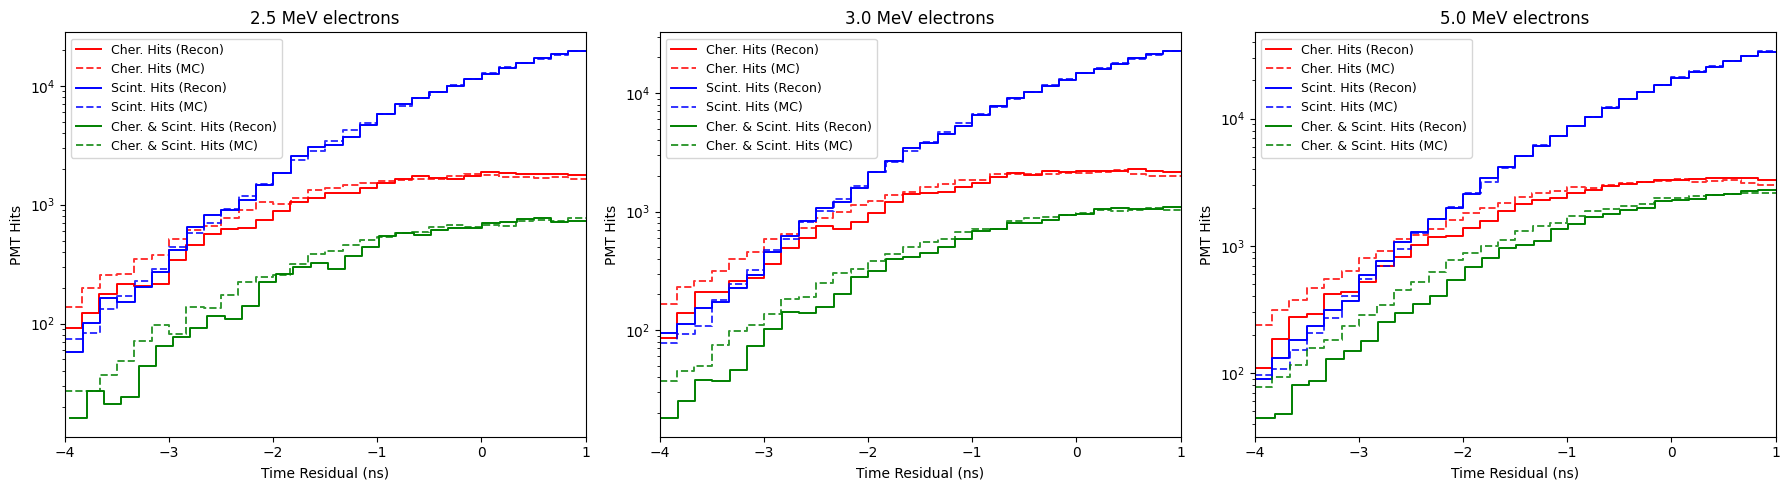

In [25]:
bins = 30

unique_energies = np.unique(data_dict['energy_mc'])

# Visual Config. (label and color) for each hit_type
hit_styles = {'cher':       {'label': 'Cher. Hits',         'color': 'red'},
              'scint':      {'label': 'Scint. Hits',        'color': 'blue'},
              'cher_scint': {'label': 'Cher. & Scint. Hits','color': 'green'}}

# Visual config for each mode: mc and recons observable
modes = {'recons': {'var': 'time_residual_recons', 'ls': '-',  'alpha': 1.0, 'lw': 1.4, 'tag': 'Recon'},
         'mc':     {'var': 'time_residual_mc',     'ls': '--', 'alpha': 0.8, 'lw': 1.4, 'tag': 'MC'}}

fig, axes = plt.subplots(1, len(unique_energies), figsize=(6 * len(unique_energies), 5), squeeze=False)
axes = axes.flatten()

for i_dx, energy_i in enumerate(unique_energies):
    ax = axes[i_dx]

    # Iteration over hit_types
    for h_name, h_style in hit_styles.items():
        # Iteration over modes (recons and mc)
        for m_name, m_cfg in modes.items():
            
            # extract data from the main dictionary (filtered data)
            energy_arr = filtered[m_name][h_name]['energy_mc']
            tres_arr = filtered[m_name][h_name][m_cfg['var']]

            # energy mask with a float tolerance
            e_mask = np.isclose(energy_arr, energy_i, atol=0.05)
            data_to_plot = tres_arr[e_mask]

            if len(data_to_plot) == 0:
                continue

            sn.histplot(data_to_plot, bins=bins, element='step', fill=False, lw=m_cfg['lw'], ls=m_cfg['ls'], color=h_style['color'], alpha=m_cfg['alpha'],
                label=f"{h_style['label']} ({m_cfg['tag']})", ax=ax)

    ax.set_xlabel('Time Residual (ns)')
    ax.set_ylabel('PMT Hits')
    ax.set_yscale('log')
    ax.set_xlim(tres_inf_cut, tres_sup_cut)
    ax.set_title(f'{energy_i:.1f} MeV electrons')
    ax.legend(loc='best', fontsize=9)

plt.tight_layout()
plt.show()

## CID 

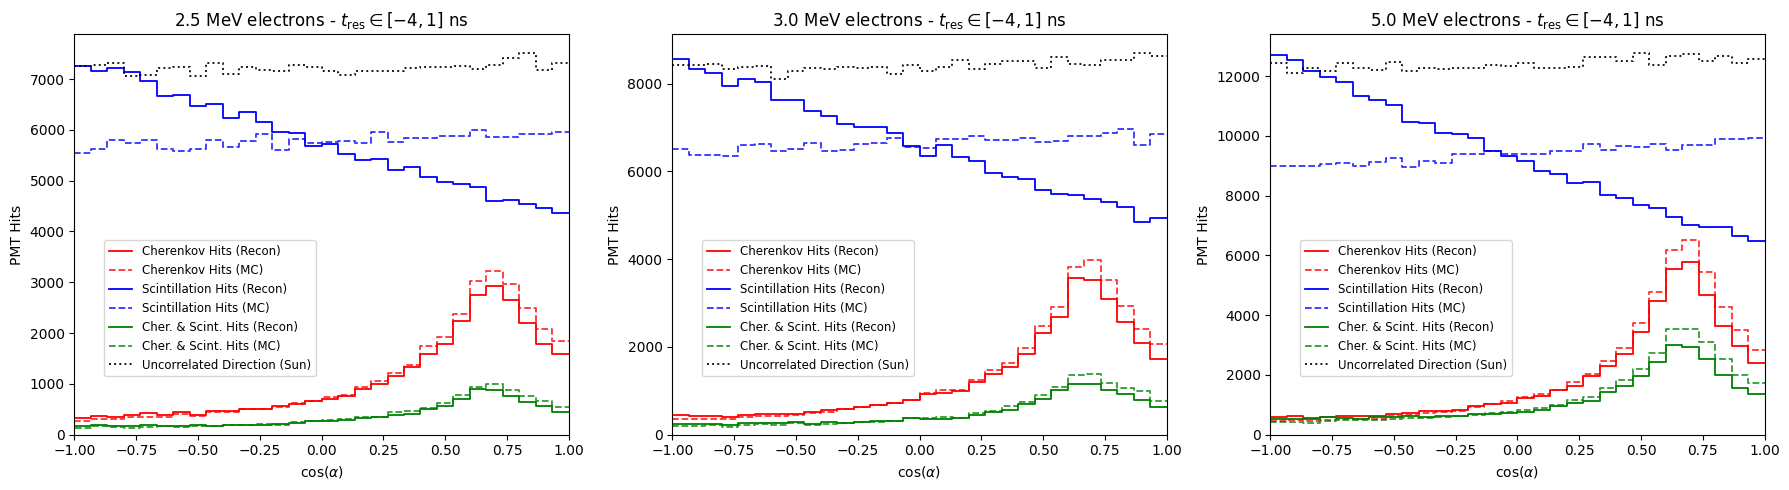

In [26]:
bins = 30
unique_energies = np.unique(data_dict['energy_mc'])

# Visual Config. (label and color) for each hit_type
hit_styles = {'cher':       {'label': 'Cherenkov Hits',              'color': 'red'},
              'scint':      {'label': 'Scintillation Hits',          'color': 'blue'},
              'cher_scint': {'label': 'Cher. & Scint. Hits',         'color': 'green'}}

# Visual config for each mode: mc and recons observable
modes = {'recons': {'var': 'dir_angle_true_recons', 'ls': '-',  'alpha': 1.0, 'lw': 1.3, 'tag': 'Recon'},
         'mc':     {'var': 'dir_angle_true_mc',     'ls': '--', 'alpha': 0.8, 'lw': 1.3, 'tag': 'MC'}}

fig, axes = plt.subplots(1, len(unique_energies), figsize=(6 * len(unique_energies), 5), squeeze=False)
axes = axes.flatten()

for i_dx, energy_i in enumerate(unique_energies):
    ax = axes[i_dx]

    # 1 Iteration over hit_types 
    for h_name, h_style in hit_styles.items():
        for m_name, m_cfg in modes.items():
            energy_arr = filtered[m_name][h_name]['energy_mc']
            angle_arr = filtered[m_name][h_name][m_cfg['var']]

            e_mask = np.isclose(energy_arr, energy_i, atol=0.05)
            data_to_plot = angle_arr[e_mask]

            if len(data_to_plot) == 0:
                continue

            sn.histplot(data_to_plot, bins=bins, element='step', fill=False, lw=m_cfg['lw'], ls=m_cfg['ls'],
                        color=h_style['color'], alpha=m_cfg['alpha'], label=f"{h_style['label']} ({m_cfg['tag']})", ax=ax)

    # 2. Uncorrelated solar direction
    # Evaluada sobre todos los hits que pasaron el corte temporal reconstruido
    sun_energy_mask = np.isclose(data_dict['energy_mc'], energy_i, atol=0.05)
    tres_recons_mask = (data_dict['time_residual_recons'] >= tres_inf_cut) & (data_dict['time_residual_recons'] <= tres_sup_cut)
    sun_data_to_plot = data_dict['dir_angle_sun'][sun_energy_mask & tres_recons_mask]

    if len(sun_data_to_plot) > 0:
        sn.histplot(sun_data_to_plot, bins=bins, element='step', fill=False, lw=1.4, ls=':',
            color='black', alpha=0.9, label='Uncorrelated Direction (Sun)', ax=ax)

    # Configuración de ejes y títulos
    ax.set_xlabel(r'$\cos(\alpha)$')
    ax.set_ylabel('PMT Hits')
    ax.set_xlim(-1, 1)
    ax.set_title(fr'{energy_i:.1f} MeV electrons - $t_\text{{res}} \in [{tres_inf_cut}, {tres_sup_cut}]$ ns')
    ax.legend(bbox_to_anchor=(0.5, 0.5), fontsize=8.5)

plt.tight_layout()
plt.show()